In [1]:
from get_data.get_data import get_merged_events
import statsbombpy
import numpy as np
import pandas as pd
from statsbombpy import sb

MATCH_ID = 3788776

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'dribbles', 'blocks', 'clearances', 'duels',
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)

events.head(5)

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress,out
0,9e9ec22a-f1cf-4460-ba53-c786f7b05287,5,1,00:00:00.080,0,0,Pass,2,Sweden,From Kick Off,...,1.422263,[b3c8e55c-581c-4c68-b722-446903bbd574],"{'recipient': {'id': 3702, 'name': 'Victor Nil...",3788776,790,5617.0,,,,
1,b3c8e55c-581c-4c68-b722-446903bbd574,6,1,00:00:01.502,0,1,Ball Receipt*,2,Sweden,From Kick Off,...,,[9e9ec22a-f1cf-4460-ba53-c786f7b05287],,3788776,790,3702.0,,,,
2,f0280b81-7d48-4071-bd0e-c479ccda4a03,7,1,00:00:01.502,0,1,Carry,2,Sweden,From Kick Off,...,1.150845,"[470d2435-f5a4-46f9-aa0c-af2ce5e92f31, b3c8e55...","{'end_location': [36.8, 41.1]}",3788776,790,3702.0,,,,
3,470d2435-f5a4-46f9-aa0c-af2ce5e92f31,8,1,00:00:02.653,0,2,Pass,2,Sweden,From Kick Off,...,3.210068,[e7e53c4b-6ee1-4f04-9a41-c4d3906d072e],"{'recipient': {'id': 5612, 'name': 'Mikael Lus...",3788776,790,3702.0,,,,
4,e7e53c4b-6ee1-4f04-9a41-c4d3906d072e,9,1,00:00:05.863,0,5,Ball Receipt*,2,Sweden,From Kick Off,...,,[470d2435-f5a4-46f9-aa0c-af2ce5e92f31],,3788776,790,5612.0,,,,


In [2]:
frames = sb.frames(MATCH_ID, fmt='dataframe')
frames.to_csv('test.csv')
frames.head(5) # type: ignore

,id,visible_area,match_id,teammate,actor,keeper,location
0,c249a6c9-9fa2-4b53-b1f5-865a60505c70,"[27.8019284858234, 80.0, 39.8323195813396, 30....",3788776,False,False,False,"[69.40095223157572, 61.70312937775431]"
1,c249a6c9-9fa2-4b53-b1f5-865a60505c70,"[27.8019284858234, 80.0, 39.8323195813396, 30....",3788776,True,False,False,"[65.92739260158025, 61.276305145191095]"
2,c249a6c9-9fa2-4b53-b1f5-865a60505c70,"[27.8019284858234, 80.0, 39.8323195813396, 30....",3788776,False,False,False,"[63.18484011960767, 52.05911953046989]"
3,c249a6c9-9fa2-4b53-b1f5-865a60505c70,"[27.8019284858234, 80.0, 39.8323195813396, 30....",3788776,False,False,False,"[64.17685632346844, 68.96885331573115]"
4,c249a6c9-9fa2-4b53-b1f5-865a60505c70,"[27.8019284858234, 80.0, 39.8323195813396, 30....",3788776,True,False,False,"[61.766687286253514, 71.09766703738244]"


In [3]:
event_id = 'c249a6c9-9fa2-4b53-b1f5-865a60505c70'
events.loc[events['id']==event_id]

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress,out
201,c249a6c9-9fa2-4b53-b1f5-865a60505c70,230,1,00:05:14.149,5,14,Ball Receipt*,15,Poland,Regular Play,...,,[e84afd51-8627-4869-b717-f93060c06380],,3788776,789,4626.0,,,,


In [4]:
from dataframe_modify.add_positions import add_positions
from dataframe_modify.swap_perspective import swap_y
from dataframe_modify.swap_perspective import generalize_perspective
from dataframe_modify.grid_areas import add_grid_areas

start_team = events['possession_team'][0]

events = add_positions(events)
events = generalize_perspective(events, start_team)
events = swap_y(events)
events = add_grid_areas(events)

In [6]:
from sequences.get_sequences import get_sequences_by_possession

sequences = get_sequences_by_possession(events)

frames.loc[frames['id'] == sequences[0].values[1][0]]

,id,visible_area,match_id,teammate,actor,keeper,location
17120,b3c8e55c-581c-4c68-b722-446903bbd574,"[77.4355834085981, 80.0, 37.0266614046705, 80....",3788776,True,True,False,"[36.099998474121094, 39.70000076293945]"
17121,b3c8e55c-581c-4c68-b722-446903bbd574,"[77.4355834085981, 80.0, 37.0266614046705, 80....",3788776,True,False,False,"[43.86066351503024, 61.42964105645084]"
17122,b3c8e55c-581c-4c68-b722-446903bbd574,"[77.4355834085981, 80.0, 37.0266614046705, 80....",3788776,True,False,False,"[37.86007123230974, 25.873666023057748]"
17123,b3c8e55c-581c-4c68-b722-446903bbd574,"[77.4355834085981, 80.0, 37.0266614046705, 80....",3788776,False,False,False,"[49.635089048435546, 46.08101899680519]"
17124,b3c8e55c-581c-4c68-b722-446903bbd574,"[77.4355834085981, 80.0, 37.0266614046705, 80....",3788776,False,False,False,"[49.41847579276105, 33.24649667200522]"
17125,b3c8e55c-581c-4c68-b722-446903bbd574,"[77.4355834085981, 80.0, 37.0266614046705, 80....",3788776,True,False,False,"[56.13716367789977, 30.617140745295558]"
17126,b3c8e55c-581c-4c68-b722-446903bbd574,"[77.4355834085981, 80.0, 37.0266614046705, 80....",3788776,True,False,False,"[58.167423667210755, 18.4721450196578]"
17127,b3c8e55c-581c-4c68-b722-446903bbd574,"[77.4355834085981, 80.0, 37.0266614046705, 80....",3788776,True,False,False,"[59.94213482477649, 23.79964968670298]"
17128,b3c8e55c-581c-4c68-b722-446903bbd574,"[77.4355834085981, 80.0, 37.0266614046705, 80....",3788776,True,False,False,"[62.171739020049024, 42.38203203618238]"
17129,b3c8e55c-581c-4c68-b722-446903bbd574,"[77.4355834085981, 80.0, 37.0266614046705, 80....",3788776,True,False,False,"[65.28507780798206, 25.847322231077037]"


In [7]:
def add_context(events, frames):
    newEvents = events
    context_locations = [frames.loc[frames['id'] == event[0]]['location'].values for event in events.values]
    newEvents['context_locations'] = context_locations
    return newEvents

In [8]:
events = add_context(events, frames)

In [9]:
from sequences.get_sequences import get_sequences_by_possession

sequences = get_sequences_by_possession(events)

Team: Sweden
1: Sebastian Larsson (Pass) <00:00:00.080>
2: Victor Nilsson Lindelöf (Ball Receipt*) <00:00:01.502>
2: Victor Nilsson Lindelöf (Carry) <00:00:01.502>
2: Victor Nilsson Lindelöf (Pass) <00:00:02.653>
3: Mikael Lustig (Ball Receipt*) <00:00:05.863>
3: Mikael Lustig (Pass) <00:00:05.863>
4: Robin Quaison (Ball Receipt*) <00:00:09.353>
4: Robin Quaison (Duel) <00:00:09.353>


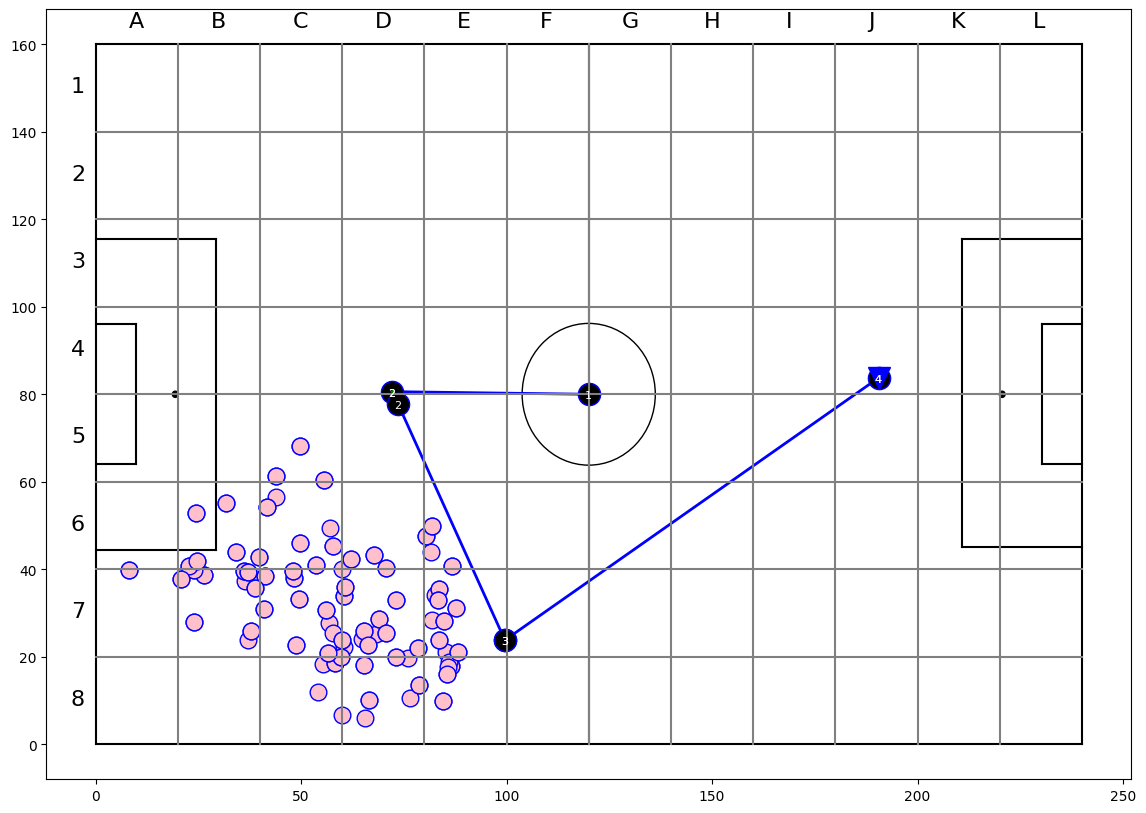

Team: Poland
1: Kamil Glik (Pass) <00:00:09.353>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:00:10.310>
2: Mateusz Andrzej Klich (Pass) <00:00:10.344>
3: Piotr Zieliński (Ball Receipt*) <00:00:11.479>
3: Piotr Zieliński (Carry) <00:00:11.479>
3: Piotr Zieliński (Pass) <00:00:13.421>
4: Robert Lewandowski (Ball Receipt*) <00:00:14.364>
4: Robert Lewandowski (Carry) <00:00:14.364>
4: Robert Lewandowski (Pass) <00:00:15.523>
5: Tymoteusz Puchacz (Ball Receipt*) <00:00:16.740>
5: Tymoteusz Puchacz (Carry) <00:00:16.740>
5: Tymoteusz Puchacz (Pass) <00:00:17.456>
6: Jan Bednarek (Ball Receipt*) <00:00:18.427>
6: Jan Bednarek (Carry) <00:00:18.427>
6: Jan Bednarek (Pass) <00:00:19.747>
7: Bartosz Bereszyński (Ball Receipt*) <00:00:21.153>
7: Bartosz Bereszyński (Carry) <00:00:21.153>
7: Bartosz Bereszyński (Pass) <00:00:25.168>
8: Kamil Glik (Ball Receipt*) <00:00:26.550>
8: Kamil Glik (Carry) <00:00:26.550>
8: Kamil Glik (Pass) <00:00:27.497>
9: Jan Bednarek (Ball Receipt*) <00:00:29.147>


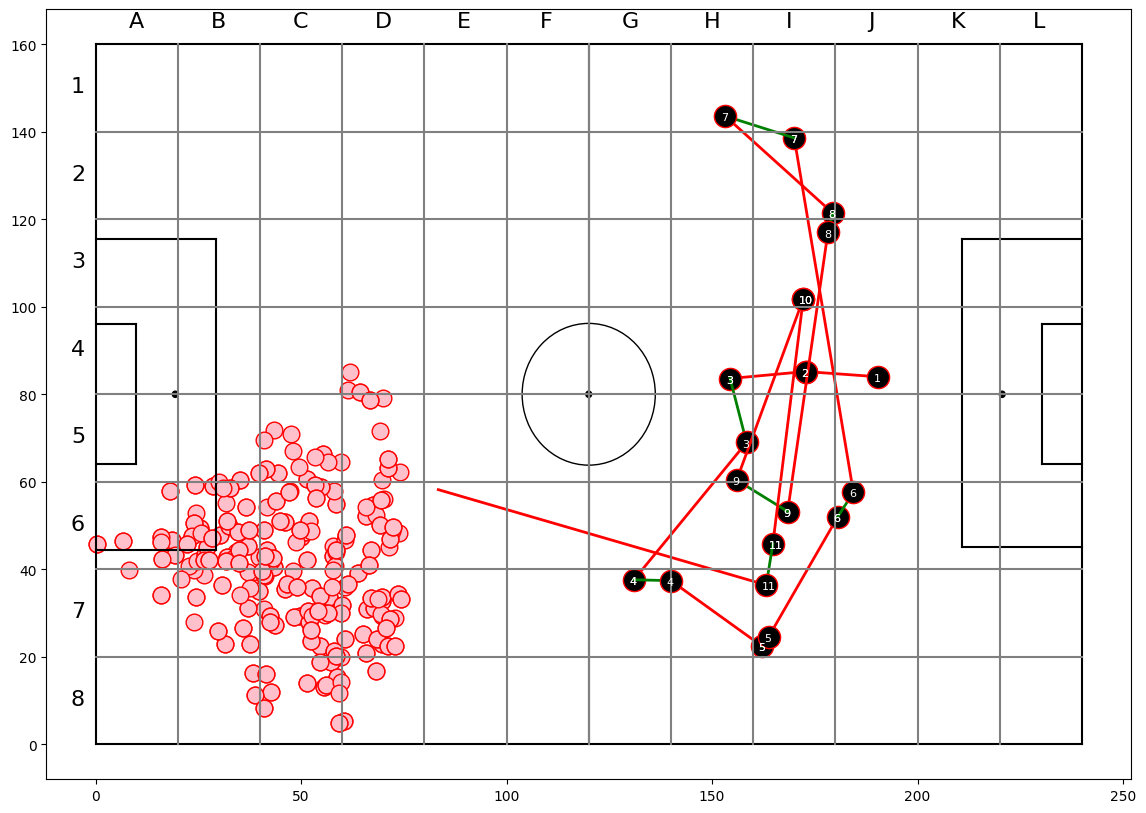

Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:00:38.375>
2: Kristoffer Olsson (Ball Receipt*) <00:00:39.466>
2: Kristoffer Olsson (Pass) <00:00:39.466>
3: Mikael Lustig (Ball Receipt*) <00:00:40.562>
3: Mikael Lustig (Carry) <00:00:40.562>
3: Mikael Lustig (Pass) <00:00:42.468>


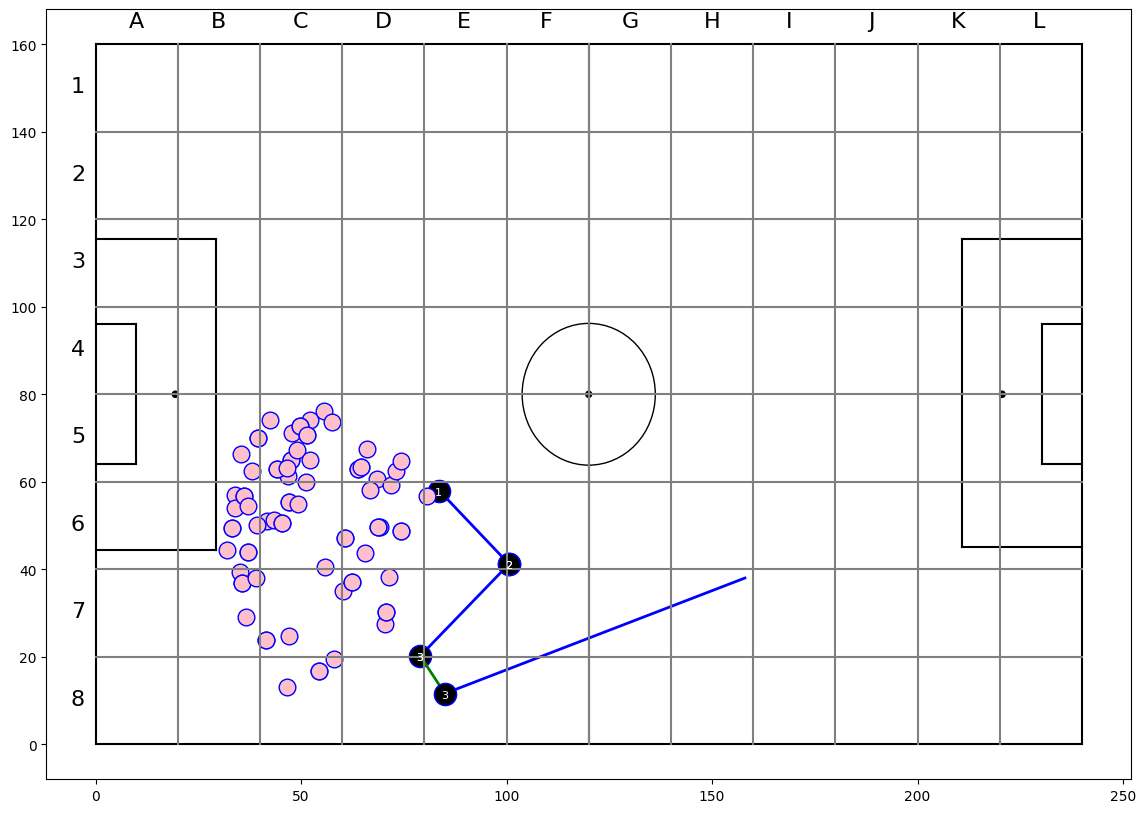

Team: Poland
1: Jan Bednarek (Pass) <00:00:44.270>
2: Grzegorz Krychowiak (Ball Receipt*) <00:00:45.101>
2: Grzegorz Krychowiak (Carry) <00:00:45.101>
2: Grzegorz Krychowiak (Pass) <00:00:46.473>
3: Tymoteusz Puchacz (Ball Receipt*) <00:00:47.194>
3: Tymoteusz Puchacz (Carry) <00:00:47.194>
3: Tymoteusz Puchacz (Pass) <00:00:47.847>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:00:48.794>
4: Mateusz Andrzej Klich (Carry) <00:00:48.794>
4: Mateusz Andrzej Klich (Dispossessed) <00:00:50.138>
5: Mikael Lustig (Duel) <00:00:50.138>


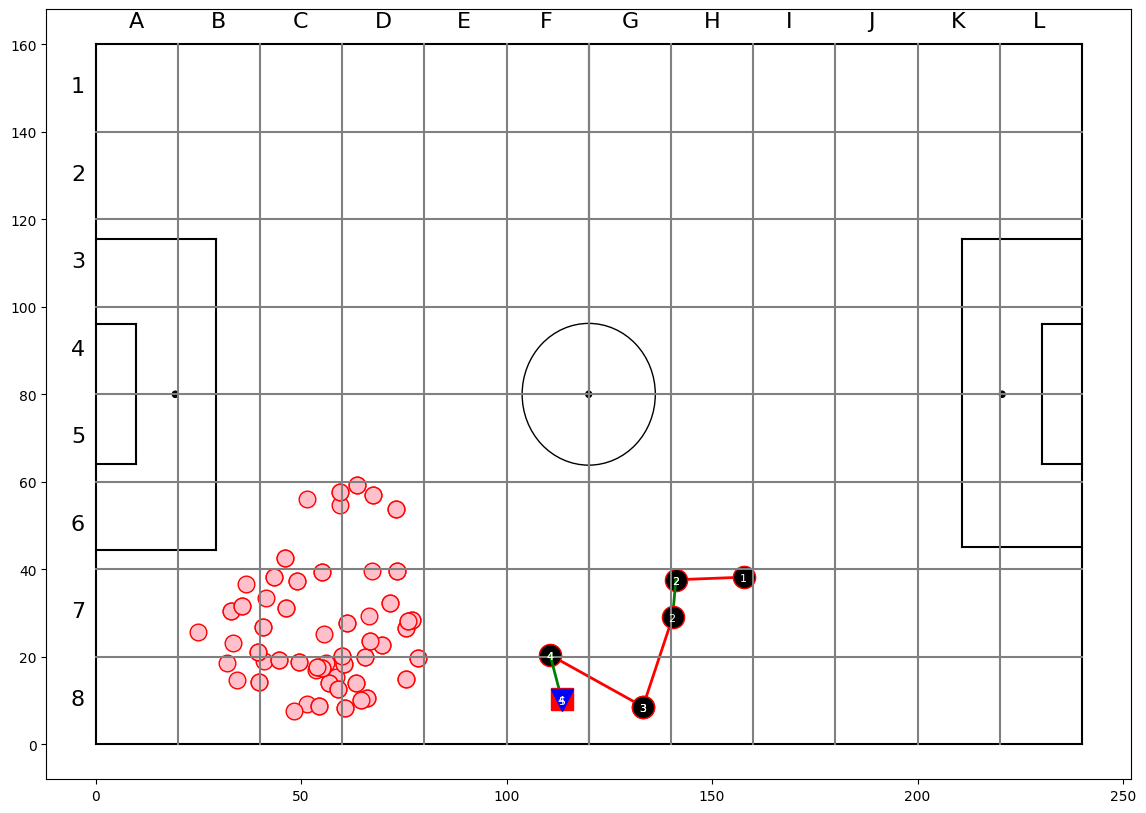

Team: Sweden
1: Mikael Lustig (Pass) <00:01:10.498>
2: Sebastian Larsson (Ball Receipt*) <00:01:11.479>
2: Sebastian Larsson (Pass) <00:01:11.479>
3: Mikael Lustig (Ball Receipt*) <00:01:12.472>
3: Mikael Lustig (Pass) <00:01:12.472>
4: Sebastian Larsson (Ball Receipt*) <00:01:13.070>
4: Sebastian Larsson (Pass) <00:01:13.070>
5: Mikael Lustig (Ball Receipt*) <00:01:14.119>
5: Mikael Lustig (Carry) <00:01:14.119>
5: Mikael Lustig (Pass) <00:01:15.083>
6: Alexander Isak (Ball Receipt*) <00:01:16.569>
6: Alexander Isak (Carry) <00:01:16.569>
6: Alexander Isak (Pass) <00:01:16.577>
7: Emil Peter Forsberg (Ball Receipt*) <00:01:17.827>
7: Emil Peter Forsberg (Carry) <00:01:17.827>
7: Emil Peter Forsberg (Pass) <00:01:17.830>
8: Alexander Isak (Ball Receipt*) <00:01:18.888>
8: Alexander Isak (Carry) <00:01:18.888>
8: Alexander Isak (Dispossessed) <00:01:19.168>
9: Kamil Glik (Duel) <00:01:19.168>
10: Emil Peter Forsberg (Pass) <00:01:19.483>
11: Alexander Isak (Ball Receipt*) <00:01:20.025>

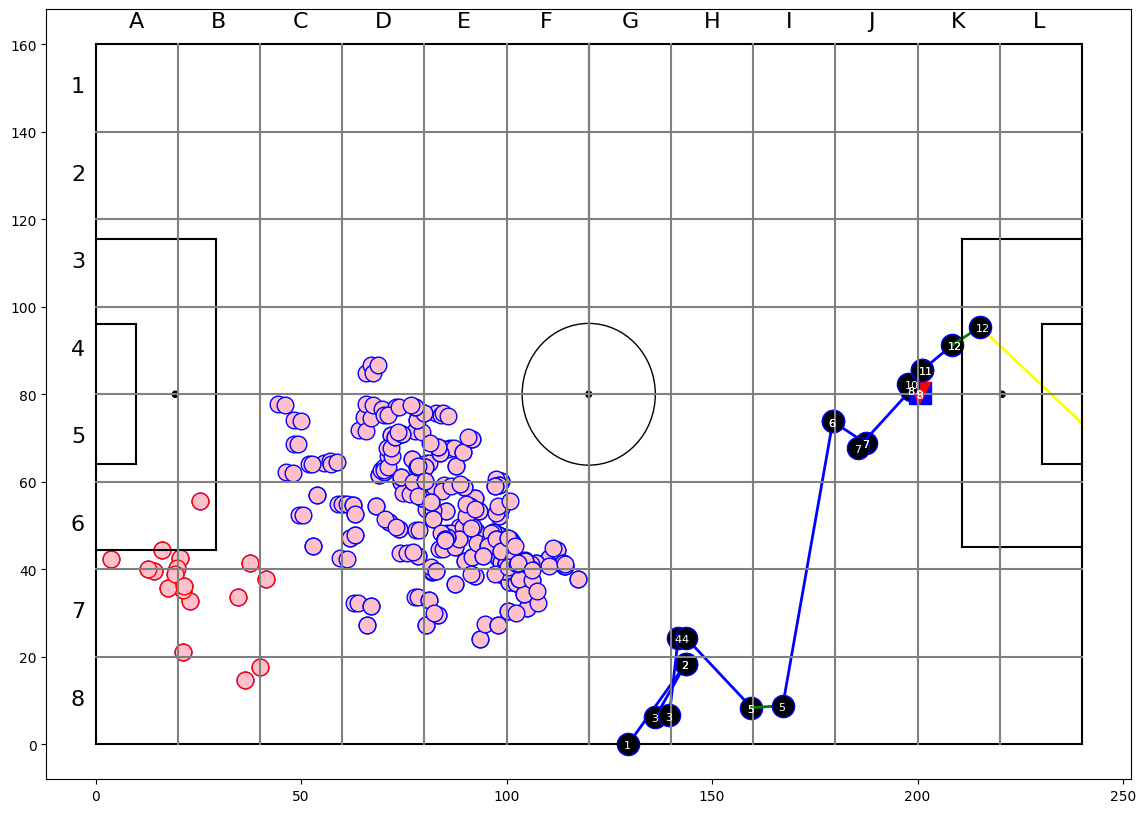

Team: Poland
1: Robert Lewandowski (Pass) <00:02:17.362>
2: Kamil Glik (Ball Receipt*) <00:02:19.016>
2: Kamil Glik (Pass) <00:02:21.722>
3: Jan Bednarek (Ball Receipt*) <00:02:23.028>
3: Jan Bednarek (Carry) <00:02:23.028>
3: Jan Bednarek (Pass) <00:02:25.583>
4: Kamil Glik (Ball Receipt*) <00:02:27.086>
4: Kamil Glik (Carry) <00:02:27.086>
4: Kamil Glik (Pass) <00:02:30.217>
5: Jan Bednarek (Ball Receipt*) <00:02:32.147>
5: Jan Bednarek (Carry) <00:02:32.147>
5: Jan Bednarek (Pass) <00:02:33.891>
6: Robert Lewandowski (Ball Receipt*) <00:02:36.609>


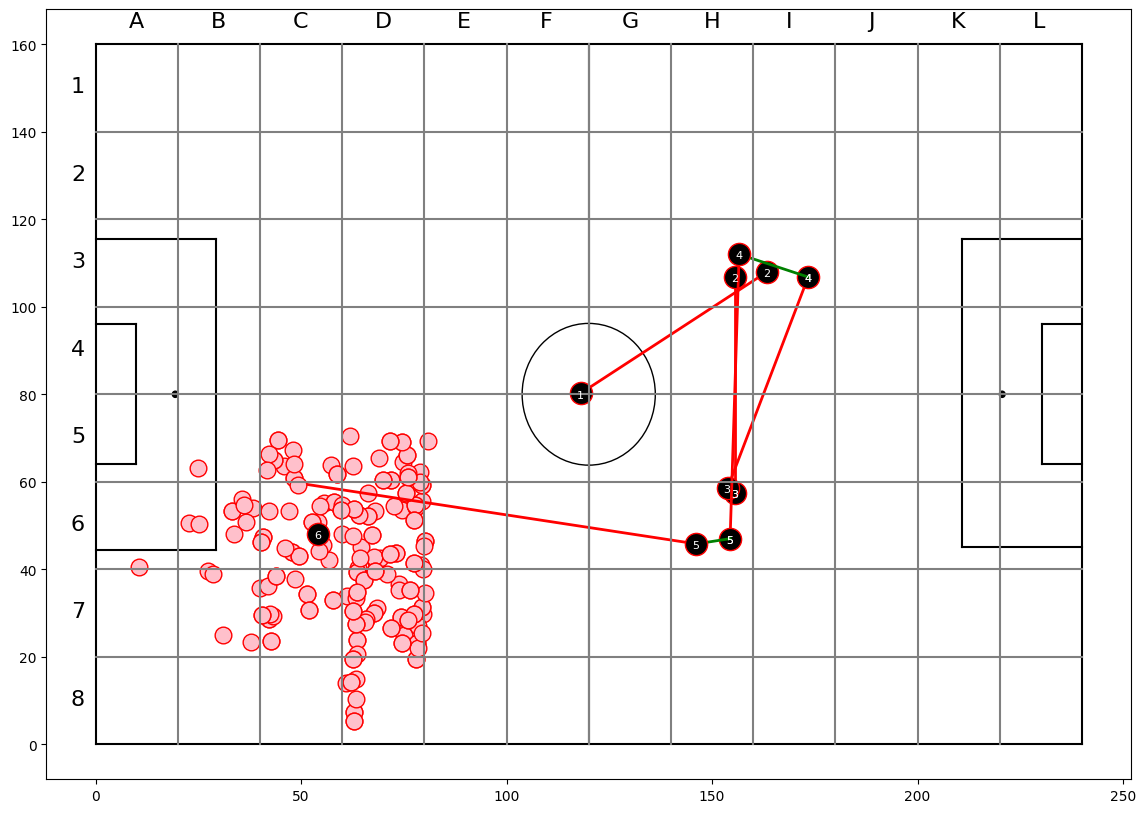

Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:02:36.609>
2: Mikael Lustig (Ball Receipt*) <00:02:38.606>
2: Mikael Lustig (Carry) <00:02:38.606>
2: Mikael Lustig (Pass) <00:02:40.897>
3: Alexander Isak (Ball Receipt*) <00:02:43.264>
3: Alexander Isak (Duel) <00:02:43.264>
4: Kamil Glik (Pass) <00:02:43.264>


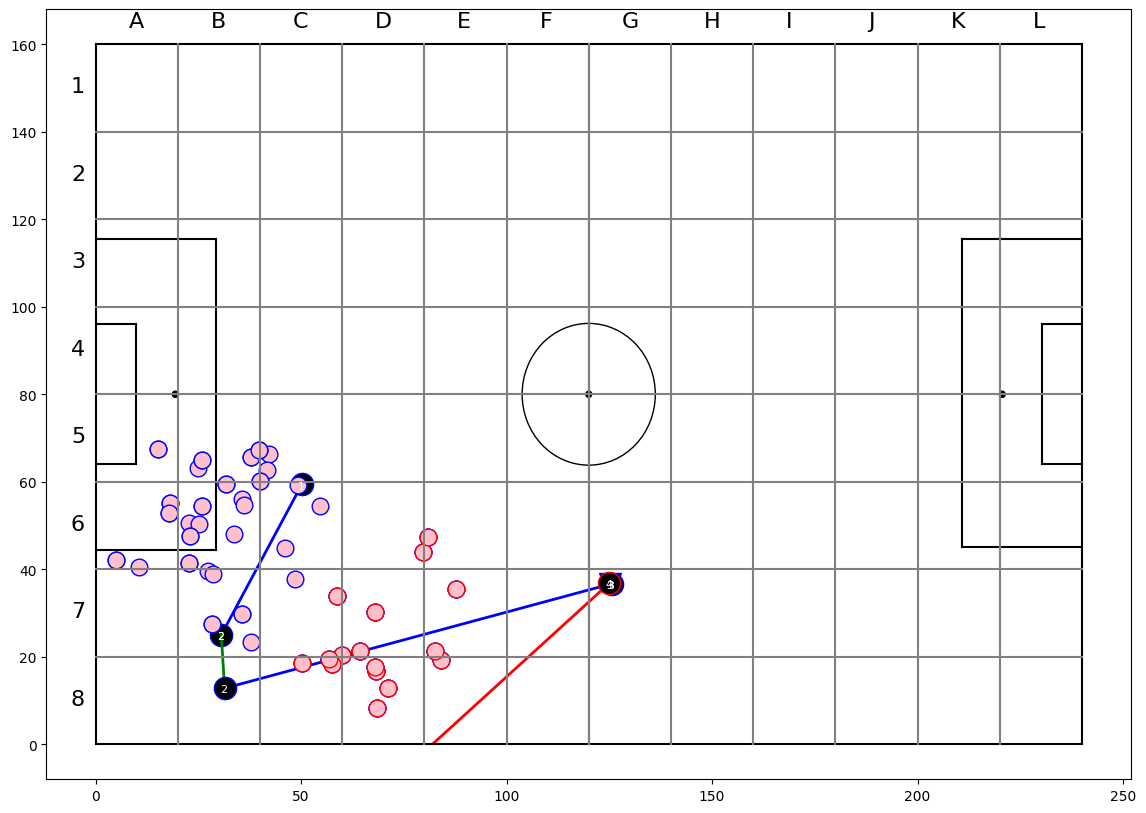

Team: Sweden
1: Mikael Lustig (Pass) <00:02:58.958>
2: Sebastian Larsson (Ball Receipt*) <00:03:00.252>
2: Sebastian Larsson (Carry) <00:03:00.252>
2: Sebastian Larsson (Pass) <00:03:00.268>
3: Mikael Lustig (Ball Receipt*) <00:03:01.146>
3: Mikael Lustig (Pass) <00:03:01.146>
4: Sebastian Larsson (Ball Receipt*) <00:03:01.294>
5: Piotr Zieliński (Block) <00:03:01.294>


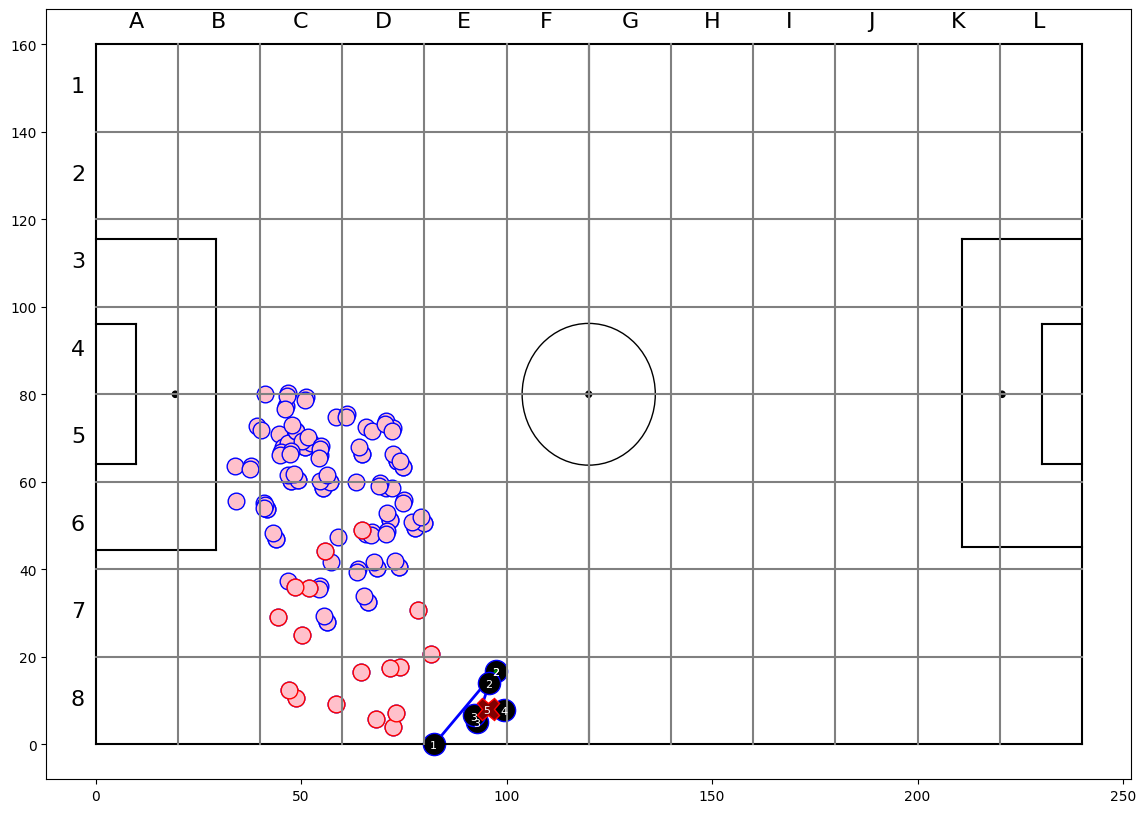

Team: Sweden
1: Mikael Lustig (Pass) <00:03:11.677>
2: Kristoffer Olsson (Ball Receipt*) <00:03:12.556>
2: Kristoffer Olsson (Pass) <00:03:12.556>
3: Mikael Lustig (Ball Receipt*) <00:03:13.491>
3: Mikael Lustig (Pass) <00:03:13.491>
4: Robin Quaison (Ball Receipt*) <00:03:16.503>
5: Kamil Glik (Pass) <00:03:16.503>
6: Tymoteusz Puchacz (Ball Receipt*) <00:03:18.134>
6: Tymoteusz Puchacz (Carry) <00:03:18.134>
6: Tymoteusz Puchacz (Pass) <00:03:19.771>
7: Marcus Andreas Danielsson (Pass) <00:03:23.681>
8: Robin Quaison (Ball Receipt*) <00:03:26.064>
9: Jan Bednarek (Duel) <00:03:26.064>
10: Robin Quaison (Pass) <00:03:26.064>
11: Emil Peter Forsberg (Ball Receipt*) <00:03:26.994>
11: Emil Peter Forsberg (Carry) <00:03:26.994>
11: Emil Peter Forsberg (Pass) <00:03:28.076>
12: Ludwig Augustinsson (Ball Receipt*) <00:03:32.879>
12: Ludwig Augustinsson (Carry) <00:03:32.879>
12: Ludwig Augustinsson (Pass) <00:03:34.011>
13: Albin Ekdal (Ball Receipt*) <00:03:35.616>
13: Albin Ekdal (Carry)

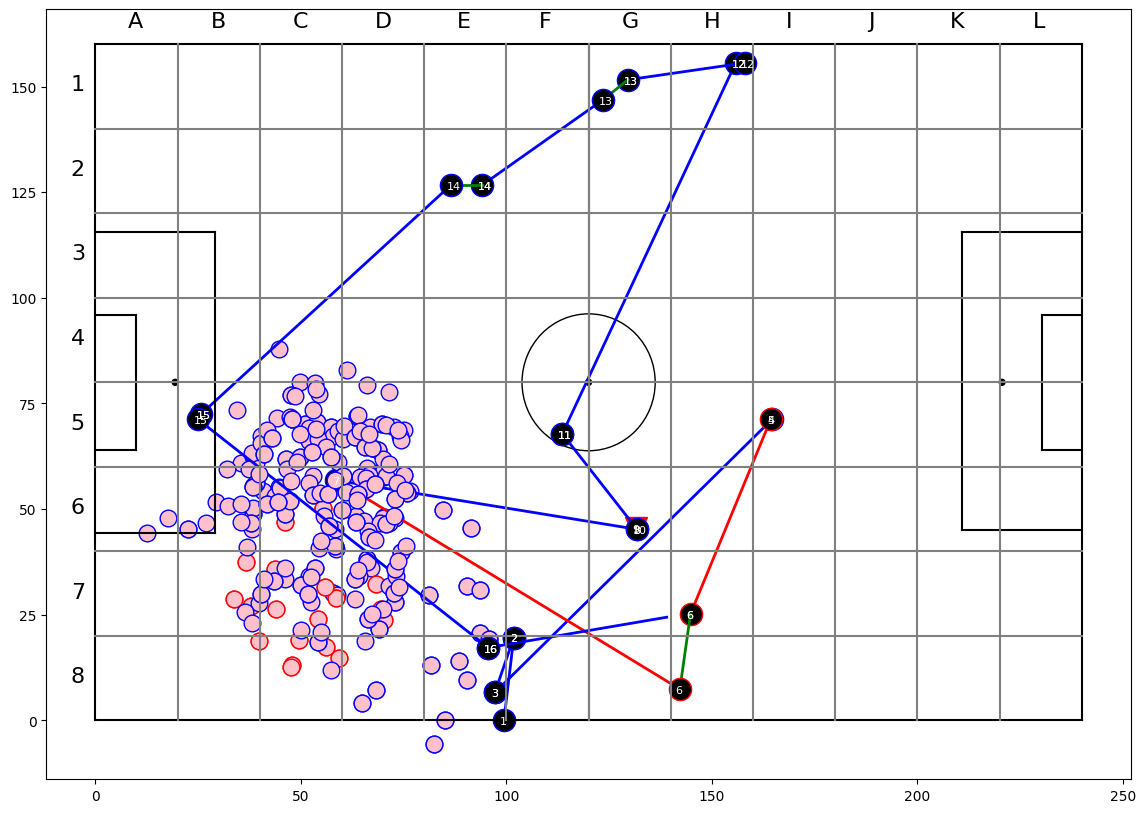

Team: Poland
1: Jan Bednarek (Pass) <00:03:53.358>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:03:54.025>
2: Mateusz Andrzej Klich (Carry) <00:03:54.025>
2: Mateusz Andrzej Klich (Pass) <00:03:54.063>
3: Grzegorz Krychowiak (Ball Receipt*) <00:03:55.019>
3: Grzegorz Krychowiak (Pass) <00:03:55.019>


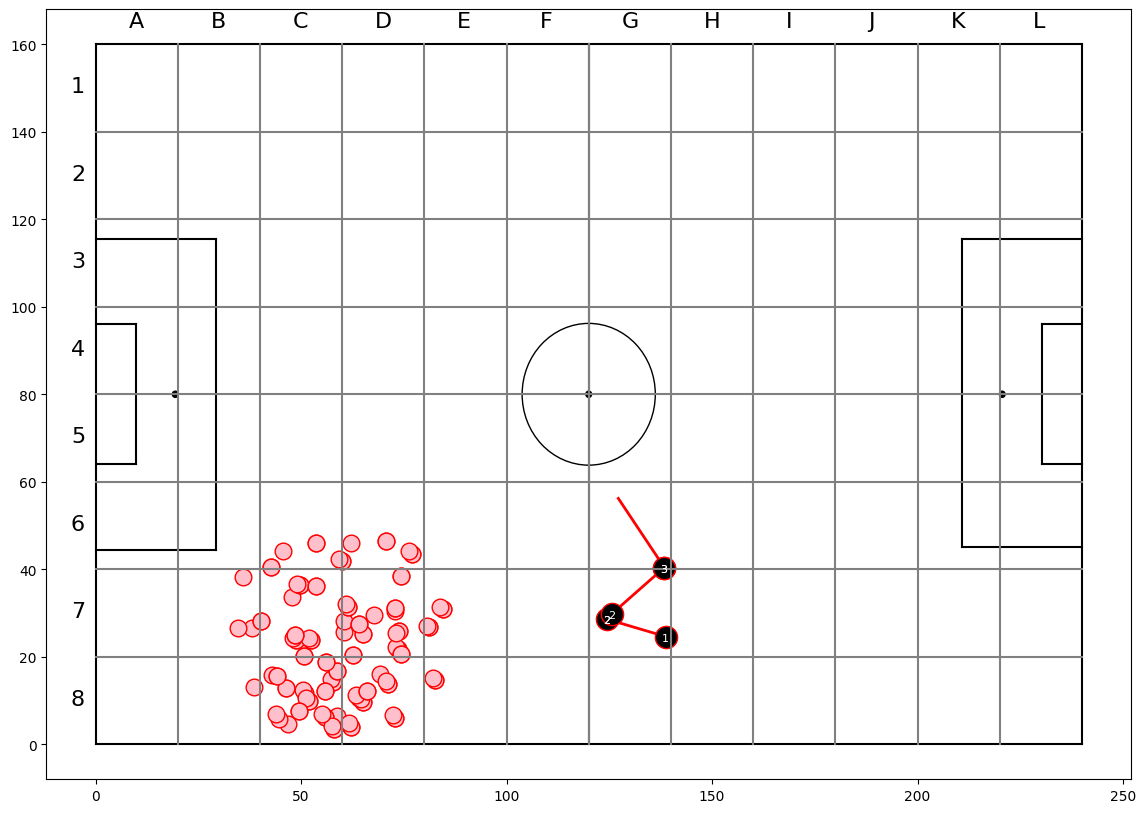

In [10]:
from draw.draw_sequences import draw_events_sequence

start_team = events['possession_team'][0]

for i, s in enumerate(sequences):
    if i == 10:
        break
    draw_events_sequence(s, start_team, 12, 8, scale=2)